# 함정 4. BN은 접고 나서 양자화해야 한다

## 고정된 BN 통계에서 양자화 순서 비교

무작위 Conv 가중치와 BN 통계를 고정하고 양자화 순서만 바꾼다. 4-bit narrow range, min/max 클립을 사용하며 최종 배포 격자는 두 경로에 동일하게 적용한다.

- A: 원래 W를 양자화 → dequantize → BN 배율로 접기 → 배포 격자로 재양자화.
- B: 원래 W를 BN 배율로 먼저 접기 → 배포 격자로 양자화.

양의 BN 배율을 사용한다. per-channel에서는 클립도 배율과 함께 변하면 균일 양자화가 배율과 교환 가능하므로 불일치가 0일 수 있다. 이 조건의 결과를 모든 양자화 방식이나 학습 중 변하는 통계에 일반화하지 않는다.

시드 0 하나로 실행한다. [학습 가이드](../docs/README.md#함정-4-bn은-접고-나서-양자화해야-한다).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m2"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.446}

In [2]:
from torch import nn
from quant_pitfalls.layers.conv_bn import QuantConvBn2d
from quant_pitfalls.quant.fake_quant import FakeQuantize
from quant_pitfalls.quant.uniform import UniformSpec, quantize, dequantize

conv = nn.Conv2d(8, 64, 3, padding=1, bias=False).to(DEVICE, dtype=torch.float64)
bn = nn.BatchNorm2d(64).to(DEVICE, dtype=torch.float64).eval()
with torch.no_grad():
    bn.running_mean.uniform_(-1, 1, generator=generator)
    bn.running_var.uniform_(0.1, 3, generator=generator)
    bn.weight.uniform_(0.1, 3, generator=generator)
    bn.bias.uniform_(-0.5, 0.5, generator=generator)
inputs = torch.randn(32, 8, 16, 16, device=DEVICE, dtype=torch.float64, generator=generator)
spec = UniformSpec(4)
rows = []
with torch.no_grad():
    reference = bn(conv(inputs))
    for label, axis in [("Per-tensor", None), ("Per-channel", 0)]:
        fq = FakeQuantize(spec, axis=axis).to(DEVICE, dtype=torch.float64)
        layer = QuantConvBn2d.from_float(conv, bn, weight_fq=fq).eval()
        folded, bias = layer.folded_weight_and_bias()
        fq(folded)
        fq.enable_observer(False)
        deployment_alpha = fq.alpha.clone()
        raw_alpha = conv.weight.abs().amax() if axis is None else conv.weight.abs().amax((1, 2, 3))
        raw_codes = quantize(conv.weight, raw_alpha, spec, axis=axis)
        raw_quantized = dequantize(raw_codes, raw_alpha, spec, axis=axis)
        factor = bn.weight / torch.sqrt(bn.running_var + bn.eps)
        naive_folded = raw_quantized * factor.reshape(-1, 1, 1, 1)
        naive_codes = quantize(naive_folded, deployment_alpha, spec, axis=axis)
        correct_codes = quantize(folded, deployment_alpha, spec, axis=axis)
        deployed_folded, _ = layer.folded_weight_and_bias()
        deployed_codes = quantize(deployed_folded, deployment_alpha, spec, axis=axis)
        naive_weight = dequantize(naive_codes, deployment_alpha, spec, axis=axis)
        correct_weight = dequantize(correct_codes, deployment_alpha, spec, axis=axis)
        naive_output = conv._conv_forward(inputs, naive_weight, bias)
        correct_output = layer(inputs)
        torch.testing.assert_close(correct_output, conv._conv_forward(inputs, correct_weight, bias))
        rows.append({"granularity": label,
                     "ordering_mismatch_pct": float((naive_codes != correct_codes).double().mean() * 100),
                     "fold_first_train_deploy_mismatch_pct": float((correct_codes != deployed_codes).double().mean() * 100),
                     "relative_weight_mse_naive": float((naive_weight - folded).square().mean() / folded.square().mean()),
                     "relative_weight_mse_correct": float((correct_weight - folded).square().mean() / folded.square().mean()),
                     "relative_output_mse_naive": float((naive_output - reference).square().mean() / reference.square().mean()),
                     "relative_output_mse_correct": float((correct_output - reference).square().mean() / reference.square().mean())})
print("Granularity | ordering mismatch (%) | fold-first train/deploy mismatch (%) | relative weight MSE A/B")
for row in rows:
    print(f"{row['granularity']:11s} | {row['ordering_mismatch_pct']:.4f} | {row['fold_first_train_deploy_mismatch_pct']:.4f} | {row['relative_weight_mse_naive']:.6f}/{row['relative_weight_mse_correct']:.6f}")


Granularity | ordering mismatch (%) | fold-first train/deploy mismatch (%) | relative weight MSE A/B
Per-tensor  | 5.9028 | 0.0000 | 0.051396/0.047602
Per-channel | 0.0000 | 0.0000 | 0.004909/0.004909


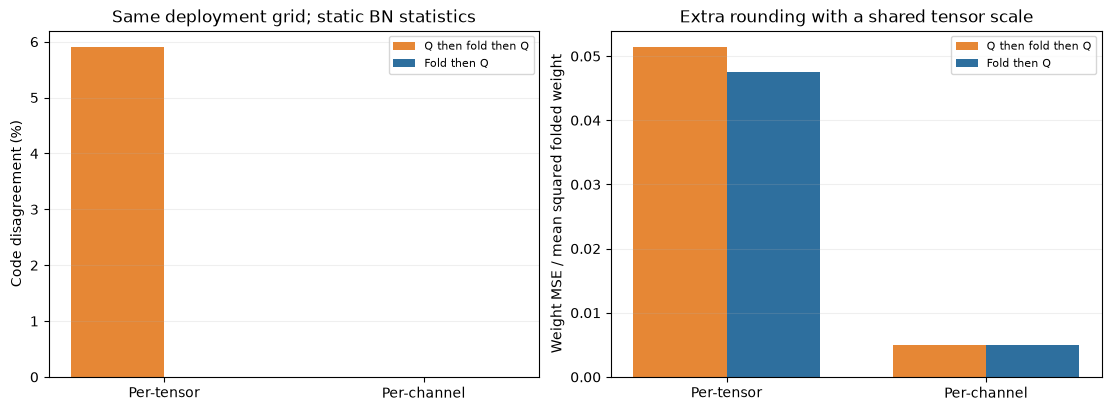

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
positions = np.arange(2)
axes[0].bar(positions - 0.18, [r["ordering_mismatch_pct"] for r in rows], width=0.36, label="Q then fold then Q", color="#E68735")
axes[0].bar(positions + 0.18, [r["fold_first_train_deploy_mismatch_pct"] for r in rows], width=0.36, label="Fold then Q", color="#2E6F9E")
axes[0].set(xticks=positions, xticklabels=[r["granularity"] for r in rows], ylabel="Code disagreement (%)", title="Same deployment grid; static BN statistics")
axes[0].legend(fontsize=8)
for offset, key, label, color in [(-0.18, "relative_weight_mse_naive", "Q then fold then Q", "#E68735"),
                                   (0.18, "relative_weight_mse_correct", "Fold then Q", "#2E6F9E")]:
    axes[1].bar(positions + offset, [r[key] for r in rows], width=0.36, label=label, color=color)
axes[1].set(xticks=positions, xticklabels=[r["granularity"] for r in rows], ylabel="Weight MSE / mean squared folded weight", title="Extra rounding with a shared tensor scale")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.savefig(FIGURES / "04_bn-folding.svg", metadata={"Date": None})
fig.savefig(RESULTS / "04_bn-folding.png", dpi=140)
plt.show()
report = {"weight_bits": 4, "positive_bn_scale": True, "static_bn_stats": True, "comparisons": rows}


## 학습 경로의 BN 보정

구현은 [Krishnamoorthi (2018), §3.2.2](https://arxiv.org/abs/1806.08342)의 보정 방식을 사용한다. running 통계로 접은 W_R=γW/σ_R을 양자화하고, 학습 중에는 convolution 결과를 σ_R/σ_B로 보정한 뒤 배치 평균으로 bias를 적용한다. BN 통계를 동결한 뒤에는 running 통계의 배포 경로로 전환한다. γ로 나누지 않아 γ=0인 채널도 처리한다.


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "04_bn-folding.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m2/04_bn-folding.json")


Saved results: runs/m2/04_bn-folding.json


## 학습된 모델의 접기 순서와 배포 정확도

같은 float 체크포인트와 학습 예산에서 두 양자화 순서를 비교한다. per-tensor/per-channel별로 학습한 뒤 배포 격자에 재양자화했을 때의 정확도와 코드 차이를 읽는다. 시드 0·1·2를 함께 비교한다.

기본 재현 명령은 저장소의 측정 기록을 사용한다. 새로운 학습 결과를 만들려면 [재현 방법](../docs/reproduction.md)의 체크포인트·학습 모드를 참고한다.


In [5]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 0.567,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


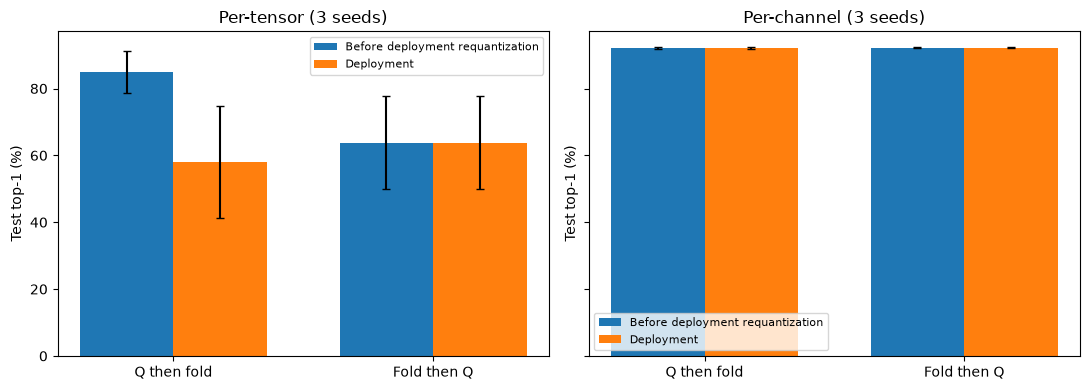

In [6]:
if READY:
    rows=REPORT['fold_order']['rows']
    fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
    for ax,granularity in zip(axes,('pt','pc')):
        x=np.arange(2)
        for offset,key,label in ((-.18,'virtual_top1','Before deployment requantization'),(.18,'deployment_top1','Deployment')):
            values=np.array([[r[key] for r in rows if r['granularity']==granularity and r['order']==order] for order in ('raw','fold')])
            ax.bar(x+offset,values.mean(1),width=.36,yerr=values.std(1,ddof=1),capsize=3,label=label)
        ax.set_xticks(x,('Q then fold','Fold then Q'))
        ax.set_title(('Per-tensor' if granularity=='pt' else 'Per-channel')+' (3 seeds)')
        ax.set_ylabel('Test top-1 (%)')
        ax.legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig,'04_bn-folding-trained')

In [7]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

고정된 가중치에서 한 BN 채널의 양의 배율만 바꿔 보자. per-tensor와 per-channel 클립에서 두 양자화 순서의 코드 차이가 왜 다른지 설명하자.
